# 06 · UMAP и автоэнкодер: проверка прежней кластерной ветки

## tl;dr

Сохранён поиск 1650 сочетаний сжатия/кластеризации. Исключение из низких ARI — AE+GMM с test ARI 0.216, но median seed-stability ARI около 0.032. Это не подтверждённый кластер риска; нового перебора по меткам нет.


## Context & Methods
### Key Assumptions
Повторно читаются все прежние кандидаты и seed/subsample-проверки, без изменения выбранной конфигурации. Исторические file-level интервалы и test не превращаются в новые независимые prefix-level доказательства. ARI с метками и ARI устойчивости — разные величины.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · полный сохранённый перебор

In [5]:
folder=ROOT/'research/experiments/ctg_uci/embeddings'
grid=pd.read_csv(folder/'joint_grid.csv');chosen=pd.read_csv(folder/'chosen_configurations.csv')
association=pd.read_csv(folder/'association.csv');stability=pd.read_csv(folder/'stability.csv')
print('Сочетаний:',len(grid));display(chosen[['method','algorithm','dimensions','k','validation_group_silhouette_common']].round(4))
display(association[association.split=='test'][['method','algorithm','ari','nmi']].round(4))


Сочетаний: 1650


,method,algorithm,dimensions,k,validation_group_silhouette_common
0,AE,FCM,2,2,0.2803
1,AE,GMM,5,2,0.2974
2,AE,KMeans,2,2,0.2803
3,PCA,FCM,2,2,0.2579
4,PCA,GMM,2,2,0.2560
5,PCA,KMeans,2,2,0.2592
6,RAW,FCM,21,2,0.2553
7,RAW,GMM,21,2,0.2893
8,RAW,KMeans,21,2,0.2541
9,UMAP,FCM,5,2,0.2541


,method,algorithm,ari,nmi
0,AE,FCM,0.0641,0.0755
3,AE,GMM,0.2159,0.1263
6,AE,KMeans,0.0641,0.0755
9,PCA,FCM,0.0483,0.1096
12,PCA,GMM,0.0717,0.1205
15,PCA,KMeans,0.0390,0.1051
18,RAW,FCM,0.0764,0.1226
21,RAW,GMM,0.0273,0.0683
24,RAW,KMeans,0.0862,0.1271
27,UMAP,FCM,-0.0104,0.0730


## Results · ассоциация и устойчивость

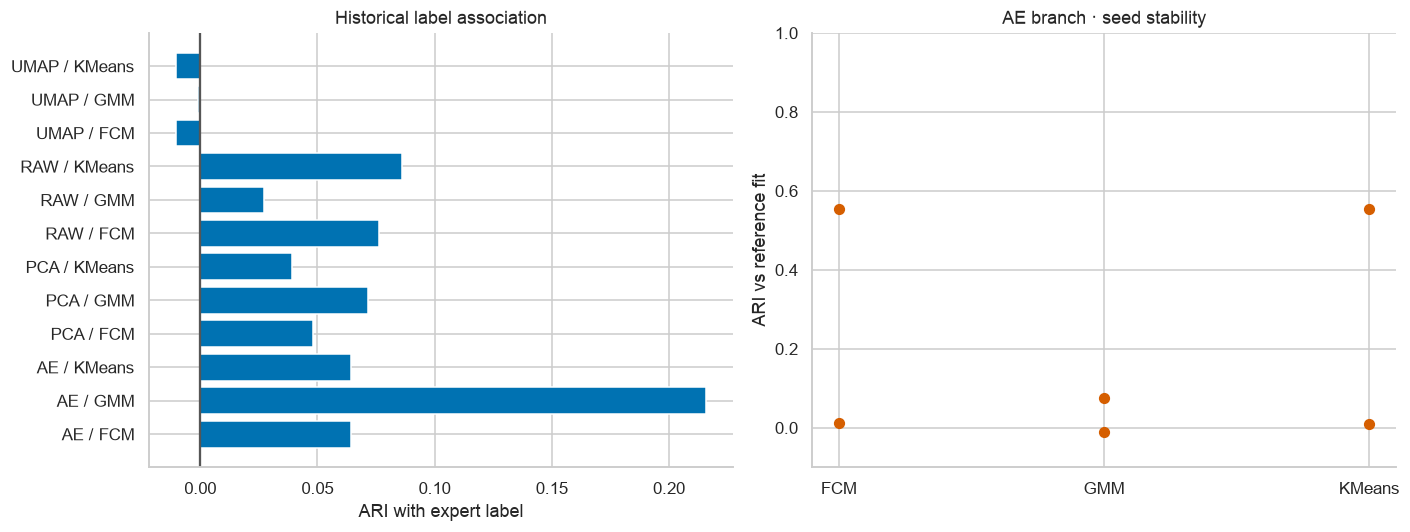

median    min    max
method algorithm mode                                
AE     FCM       file_subsample   0.712  0.475  0.795
                 seed             0.283  0.012  0.555
       GMM       file_subsample   0.131 -0.033  0.714
                 seed             0.032 -0.010  0.075
       KMeans    file_subsample   0.692  0.487  0.782
                 seed             0.281  0.009  0.553
PCA    FCM       file_subsample   0.942  0.908  0.953
                 seed             1.000  1.000  1.000
       GMM       file_subsample   0.886  0.737  0.977
                 seed             0.965  0.953  0.977
       KMeans    file_subsample   0.931  0.897  0.988
                 seed             0.994  0.988  1.000
RAW    FCM       file_subsample   0.953  0.842  0.977
                 seed             1.000  1.000  1.000
       GMM       file_subsample   0.885  0.675  0.987
                 seed             1.000  1.000  1.000
       KMeans    file_subsample   0.931  0.678  1.000
                 seed             1.000  1.000  1.000
UMAP   FCM       file_subsample   0.918  0.593  0.941
                 seed             0.930  0.918  0.941
       GMM       file_subsample   0.838  0.262  0.916
                 seed             0.935  0.894  0.976
       KMeans    file_subsample   0.918  0.557  0.941
                 seed             0.947  0.941  0.953

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
z=association[association.split=='test'].copy();z['label']=z.method+' / '+z.algorithm
axes[0].barh(z.label,z.ari,color='#0072b2');axes[0].axvline(0,color='#555555');axes[0].set(xlabel='ARI with expert label',title='Historical label association')
s=stability[(stability.method=='AE')&(stability['mode']=='seed')]
for i,algorithm in enumerate(['FCM','GMM','KMeans']):
    a=s[s.algorithm==algorithm];axes[1].scatter(np.full(len(a),i),a.validation_ari_vs_reference,color='#d55e00',s=40)
axes[1].set(xticks=range(3),xticklabels=['FCM','GMM','KMeans'],ylabel='ARI vs reference fit',ylim=(-.1,1),title='AE branch · seed stability')
fig.tight_layout();save_show('uci06_embeddings_closed.png')
display(stability.groupby(['method','algorithm','mode']).validation_ari_vs_reference.agg(['median','min','max']).round(3))


## Takeaways
AE+GMM выделяется численной ассоциацией, но её seed-устойчивость недостаточна. Сохранить отрицательный/неустойчивый результат полезнее нового перебора до красивого разделения. Ни UMAP, ни AE не включены в классификатор приложения.
